# Galaxy Zoo 2 EDA: bars and spiral-arm tightness

**Research question:** does a Vision Transformer beat a CNN at detecting **bars** (GZ2 question
`t03`) and at estimating **spiral-arm tightness** (`t10`)?

This notebook answers the data questions that decide how that comparison is set up:

1. **How many usable labels are there?**
2. **How clean are the labels?** How ambiguous are the volunteer votes?
3. **What do the targets look like?** Class balance, and baselines a model has to beat.
4. **Which galaxies end up labelled?**
5. **How much real detail is in each image?** This sets the input size, and the patch size for a ViT.

**Prerequisite:** `uv run dvc pull && uv run dvc repro` (see the README).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

from gz2.data import RAW_DIR, ROOT, load_galaxies

MIN_VOTES = 10          # minimum volunteers on a question for its label to count
BAR_THRESHOLD = 0.5     # debiased bar fraction at or above
CONFIDENT = 0.8         # vote share treated as a confident label
SDSS_ARCSEC_PER_PX = 0.396
WINDING_COLS = ["t10_tight", "t10_medium", "t10_loose"]
WINDING_NAMES = ["tight", "medium", "loose"]

OUTPUT_DIR = ROOT / "output"
OUTPUT_DIR.mkdir(exist_ok=True)

# One colour per question, used consistently in every chart
BAR_COLOR, WINDING_COLOR = "#2a78d6", "#eb6834"
INK, INK_SECONDARY, SURFACE = "#0b0b0b", "#52514e", "#fcfcfb"

plt.rcParams.update({
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_SECONDARY,
    "ytick.color": INK_SECONDARY,
    "axes.titlelocation": "left",
    "figure.dpi": 110,
})
pd.set_option("display.max_columns", 40)


def save(fig: plt.Figure, name: str) -> None:
    fig.tight_layout()
    fig.savefig(OUTPUT_DIR / f"eda_{name}.png")
    plt.show()

## Load

`load_galaxies()` (in `gz2/data.py`) returns one row per galaxy with debiased vote fractions,
`tNN_votes` (how many volunteers answered each question) and image paths. We add redshift,
brightness and size from `gz2sample`

In [2]:
df = load_galaxies()

photometry = (
    pd.read_csv(RAW_DIR / "gz2sample.csv.gz", usecols=["OBJID", "REDSHIFT", "PETROR90_R", "PETROMAG_R"])
    .rename(columns={"OBJID": "dr7objid", "REDSHIFT": "redshift", "PETROR90_R": "petro_r90_arcsec",
                     "PETROMAG_R": "r_mag"})
)
df = df.merge(photometry, on="dr7objid", how="left", validate="one_to_one")
df["native_px"] = 2 * df["petro_r90_arcsec"] / SDSS_ARCSEC_PER_PX

df["bar_usable"] = (df["t03_votes"] >= MIN_VOTES) & df["t03_bar"].notna() & df["has_image"]
df["winding_usable"] = (df["t10_votes"] >= MIN_VOTES) & df[WINDING_COLS].notna().all(axis=1) & df["has_image"]

print(f"{len(df):,} galaxies | photometry matched for {df['redshift'].notna().mean():.1%}")
df[["dr7objid", "gz2_class", "t03_bar", "t03_votes", *WINDING_COLS, "t10_votes", "redshift", "native_px"]].head()

239,695 galaxies | photometry matched for 100.0%


,dr7objid,gz2_class,t03_bar,t03_votes,t10_tight,t10_medium,t10_loose,t10_votes,redshift,native_px
0,587732591714893851,Sc+t,0.025,40,0.676487,0.301320,0.025,40,0.033206,147.726838
1,588009368545984617,Sb+t,0.080,41,0.871056,0.080068,0.050,41,0.030169,152.796919
2,587732484359913515,Ei,0.400,5,0.000000,0.000000,0.000,0,0.030461,144.577268
3,587741723357282317,Sc+t,0.038,26,0.640306,0.319844,0.040,25,0.030209,132.463051
4,587738410866966577,Er,0.000,7,0.000000,0.000000,0.000,0,0.032621,159.519505


## 1. How many usable labels?

GZ2 is a decision tree. A volunteer is only asked "is there a bar?" after answering *features or
disk* and *not edge-on*, and "how tight are the arms?" only after also answering *spiral*. Every
galaxy got about 43 classifications, but the bar and winding questions received far fewer.

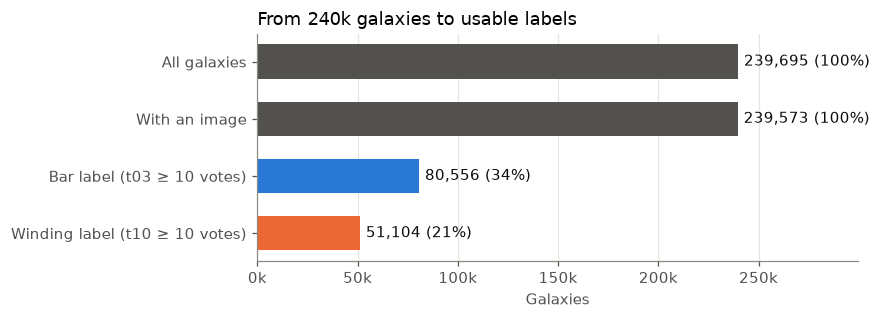

Median volunteers per galaxy: t01 43, t03 (bar) 5, t10 (winding) 1


In [3]:
funnel = pd.Series({
    "All galaxies": len(df),
    "With an image": int(df["has_image"].sum()),
    f"Bar label (t03 ≥ {MIN_VOTES} votes)": int(df["bar_usable"].sum()),
    f"Winding label (t10 ≥ {MIN_VOTES} votes)": int(df["winding_usable"].sum()),
})

fig, ax = plt.subplots(figsize=(8, 3))
colors = [INK_SECONDARY, INK_SECONDARY, BAR_COLOR, WINDING_COLOR]
bars = ax.barh(funnel.index[::-1], funnel.values[::-1], color=colors[::-1], height=0.6)
ax.bar_label(bars, labels=[f"{v:,} ({v / funnel.iloc[0]:.0%})" for v in funnel.values[::-1]],
             padding=4, color=INK)
ax.set_xlim(0, funnel.max() * 1.25)
ax.xaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_xlabel("Galaxies")
ax.set_title("From 240k galaxies to usable labels")
ax.grid(axis="y", visible=False)
save(fig, "label_funnel")

print(f"Median volunteers per galaxy: t01 {df['t01_votes'].median():.0f}, "
      f"t03 (bar) {df['t03_votes'].median():.0f}, t10 (winding) {df['t10_votes'].median():.0f}")

### Choosing the vote cutoff

A higher `MIN_VOTES` gives cleaner labels but fewer of them. The chart shows what each cutoff costs.

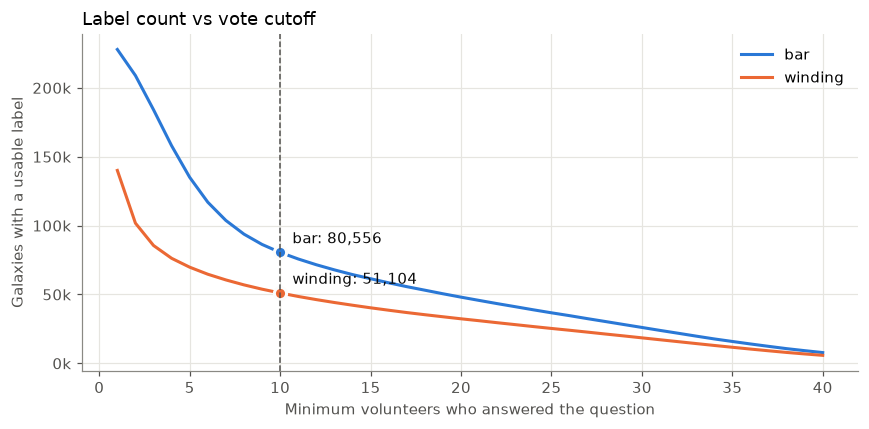

,bar,winding
5,"135,049","69,804"
10,"80,556","51,104"
15,"61,440","40,324"
20,"48,059","32,339"
30,"26,063","18,515"


In [4]:
cutoffs = np.arange(1, 41)
available = pd.DataFrame({
    "bar": [int(((df["t03_votes"] >= k) & df["has_image"]).sum()) for k in cutoffs],
    "winding": [int(((df["t10_votes"] >= k) & df["has_image"]).sum()) for k in cutoffs],
}, index=cutoffs)

fig, ax = plt.subplots(figsize=(8, 4))
for name, color in (("bar", BAR_COLOR), ("winding", WINDING_COLOR)):
    ax.plot(available.index, available[name], color=color, linewidth=2, label=name)
    ax.annotate(f"{name}: {available.loc[MIN_VOTES, name]:,}", xy=(MIN_VOTES, available.loc[MIN_VOTES, name]),
                xytext=(8, 6), textcoords="offset points", color=INK)
    ax.plot(MIN_VOTES, available.loc[MIN_VOTES, name], "o", color=color, markersize=8,
            markeredgecolor=SURFACE, markeredgewidth=2)
ax.axvline(MIN_VOTES, color=INK_SECONDARY, linewidth=1, linestyle="--")
ax.yaxis.set_major_formatter(lambda v, _: f"{v / 1000:.0f}k")
ax.set_xlabel("Minimum volunteers who answered the question")
ax.set_ylabel("Galaxies with a usable label")
ax.set_title("Label count vs vote cutoff")
ax.legend(frameon=False)
save(fig, "vote_cutoff")

available.loc[[5, 10, 15, 20, 30]].style.format("{:,}")

## 2. How clean are the labels?

Each label is a **debiased vote fraction**, not a hard class. Fractions near 0 or 1 are confident;
values near 0.5 mean volunteers disagreed. A model can't be more certain than the labels, so the
share of ambiguous galaxies limits how high accuracy can go.

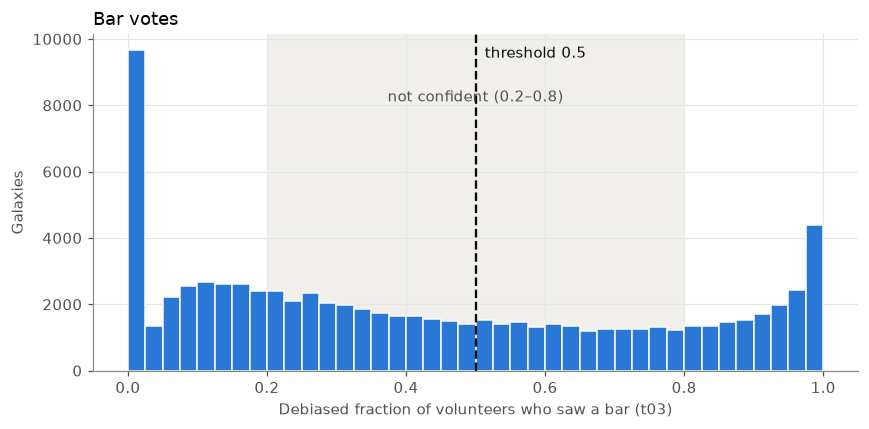

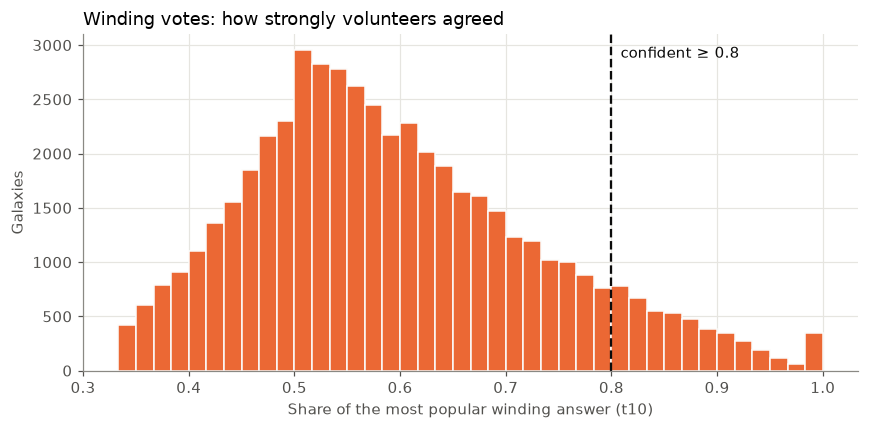

,usable labels,confident (≥ 0.8),ambiguous (0.35–0.65 / max < 0.5)
bar (t03),"80,556",52.5%,22.3%
winding (t10),"51,104",9.2%,26.6%


In [5]:
bar_frac = df.loc[df["bar_usable"], "t03_bar"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.axvspan(1 - CONFIDENT, CONFIDENT, color="#e6e5e0", alpha=0.6, linewidth=0)
ax.hist(bar_frac, bins=40, range=(0, 1), color=BAR_COLOR, edgecolor=SURFACE, linewidth=1)
ax.axvline(BAR_THRESHOLD, color=INK, linewidth=1.5, linestyle="--")
ax.annotate(f"threshold {BAR_THRESHOLD}", xy=(BAR_THRESHOLD, ax.get_ylim()[1] * 0.93),
            xytext=(6, 0), textcoords="offset points", color=INK)
ax.annotate(f"not confident ({1 - CONFIDENT:.1f}–{CONFIDENT})", xy=(0.5, ax.get_ylim()[1] * 0.80), ha="center",
            color=INK_SECONDARY)
ax.set_xlabel("Debiased fraction of volunteers who saw a bar (t03)")
ax.set_ylabel("Galaxies")
ax.set_title("Bar votes")
save(fig, "bar_fraction")

winding = df.loc[df["winding_usable"], WINDING_COLS]
winding_max = winding.max(axis=1)

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(winding_max, bins=40, range=(1 / 3, 1), color=WINDING_COLOR, edgecolor=SURFACE, linewidth=1)
ax.axvline(CONFIDENT, color=INK, linewidth=1.5, linestyle="--")
ax.annotate(f"confident ≥ {CONFIDENT}", xy=(CONFIDENT, ax.get_ylim()[1] * 0.93),
            xytext=(6, 0), textcoords="offset points", color=INK)
ax.set_xlabel("Share of the most popular winding answer (t10)")
ax.set_ylabel("Galaxies")
ax.set_title("Winding votes: how strongly volunteers agreed")
save(fig, "winding_agreement")

label_quality = pd.DataFrame({
    "usable labels": [len(bar_frac), len(winding)],
    f"confident (≥ {CONFIDENT})": [((bar_frac >= CONFIDENT) | (bar_frac <= 1 - CONFIDENT)).mean(),
                                   (winding_max >= CONFIDENT).mean()],
    "ambiguous (0.35–0.65 / max < 0.5)": [bar_frac.between(0.35, 0.65).mean(), (winding_max < 0.5).mean()],
}, index=["bar (t03)", "winding (t10)"])
label_quality.style.format({"usable labels": "{:,}", f"confident (≥ {CONFIDENT})": "{:.1%}",
                            "ambiguous (0.35–0.65 / max < 0.5)": "{:.1%}"})

## 3. What do the targets look like?

- **Bar** is a binary target: barred if the debiased fraction ≥ `BAR_THRESHOLD`.
- **Winding** is a regression target: the (tight, medium, loose) vote fractions. The bars show
  which answer won most often.

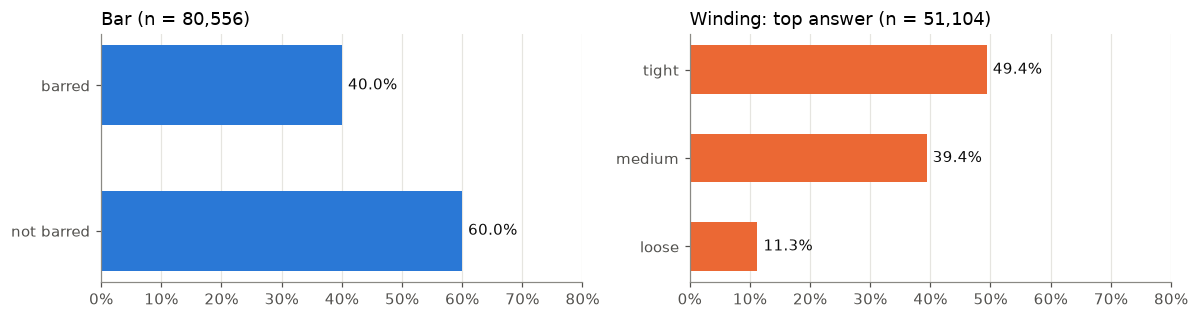

In [6]:
barred_share = (bar_frac >= BAR_THRESHOLD).mean()
winding_winner = (
    winding.idxmax(axis=1).map(dict(zip(WINDING_COLS, WINDING_NAMES)))
    .value_counts(normalize=True).reindex(WINDING_NAMES)
)

fig, (ax_bar, ax_wind) = plt.subplots(1, 2, figsize=(11, 3))
b = ax_bar.barh(["not barred", "barred"], [1 - barred_share, barred_share], color=BAR_COLOR, height=0.55)
ax_bar.bar_label(b, labels=[f"{v:.1%}" for v in (1 - barred_share, barred_share)], padding=4, color=INK)
ax_bar.set_title(f"Bar (n = {len(bar_frac):,})")
w = ax_wind.barh(WINDING_NAMES[::-1], winding_winner.values[::-1], color=WINDING_COLOR, height=0.55)
ax_wind.bar_label(w, labels=[f"{v:.1%}" for v in winding_winner.values[::-1]], padding=4, color=INK)
ax_wind.set_title(f"Winding: top answer (n = {len(winding):,})")
for ax in (ax_bar, ax_wind):
    ax.set_xlim(0, 0.8)
    ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    ax.grid(axis="y", visible=False)
save(fig, "target_balance")

### Trivial baselines vs the proposal's targets

These are what a model scores by **ignoring the image**: always predict the majority bar class,
or always predict the average winding fractions. The CNN and ViT both need to clear them
comfortably. The "confident only" rows show how much restricting to clean labels changes the picture.

In [7]:
def bar_majority_accuracy(fractions: pd.Series) -> float:
    labels = fractions >= BAR_THRESHOLD
    return max(labels.mean(), 1 - labels.mean())


def winding_mean_rmse(fractions: pd.DataFrame) -> float:
    values = fractions.to_numpy()
    values = values / values.sum(axis=1, keepdims=True)  # renormalise, as in the training notebook
    return float(np.sqrt(((values - values.mean(axis=0)) ** 2).mean()))


confident_bar = bar_frac[(bar_frac >= CONFIDENT) | (bar_frac <= 1 - CONFIDENT)]
confident_winding = winding[winding_max >= CONFIDENT]

baselines = pd.DataFrame({
    "bar accuracy (majority class)": [bar_majority_accuracy(bar_frac), bar_majority_accuracy(confident_bar), 0.90],
    "winding RMSE (predict the mean)": [winding_mean_rmse(winding), winding_mean_rmse(confident_winding), 0.10],
    "n bar / n winding": [f"{len(bar_frac):,} / {len(winding):,}",
                          f"{len(confident_bar):,} / {len(confident_winding):,}", ""],
}, index=["all usable labels", f"confident only (≥ {CONFIDENT})", "proposal target"])
baselines.style.format({"bar accuracy (majority class)": "{:.3f}", "winding RMSE (predict the mean)": "{:.3f}"})

,bar accuracy (majority class),winding RMSE (predict the mean),n bar / n winding
all usable labels,0.600,0.203,"80,556 / 51,104"
confident only (≥ 0.8),0.616,0.288,"42,320 / 4,712"
proposal target,0.900,0.100,


### Are the two targets related?

The two heads share a backbone, so it helps to know whether the targets carry overlapping
information. Below are the average winding fractions for barred and unbarred spirals.

In [8]:
both = df[df["bar_usable"] & df["winding_usable"]].copy()
both["barred"] = np.where(both["t03_bar"] >= BAR_THRESHOLD, "barred", "not barred")
winding_by_bar = both.groupby("barred")[WINDING_COLS].mean().set_axis(WINDING_NAMES, axis=1)

print(f"{len(both):,} galaxies have both labels")
print("Correlation of bar fraction with winding fractions:",
      both[["t03_bar", *WINDING_COLS]].corr().loc["t03_bar", WINDING_COLS].round(2).to_dict())
winding_by_bar.style.format("{:.3f}")

51,103 galaxies have both labels
Correlation of bar fraction with winding fractions: {'t10_tight': -0.28, 't10_medium': 0.14, 't10_loose': 0.16}


,tight,medium,loose
barred,,,
barred,0.370,0.410,0.178
not barred,0.493,0.376,0.124


## 4. Which galaxies end up labelled?

Volunteers only reach the bar and arm questions when they can see a disk and its structure. So
labels are **concentrated in large, nearby galaxies**. The test set will therefore over-represent
easier, well-resolved galaxies, and results should be reported **per size bin** as well as overall.

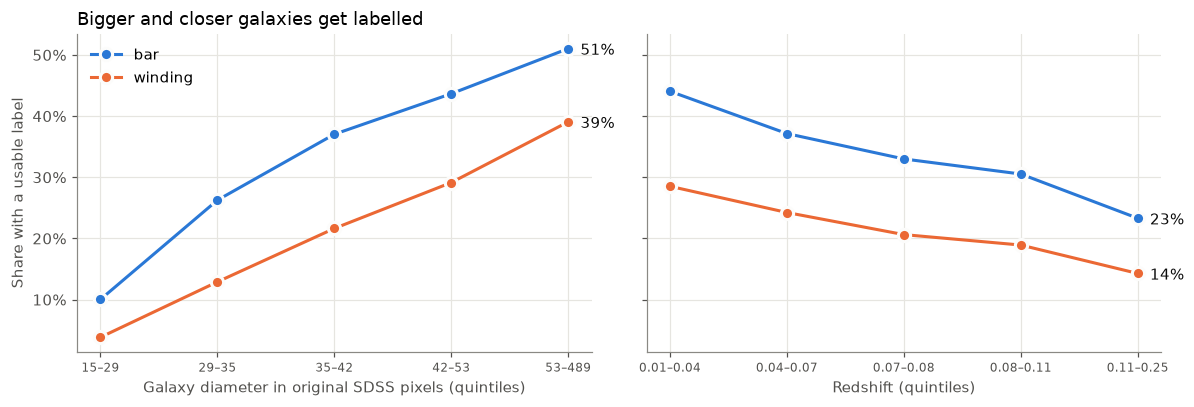

In [9]:
df["size_bin"] = pd.qcut(df["native_px"], 5)
df["z_bin"] = pd.qcut(df["redshift"], 5)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, (col, xlabel) in zip(axes, [("size_bin", "Galaxy diameter in original SDSS pixels (quintiles)"),
                                     ("z_bin", "Redshift (quintiles)")]):
    share = df.groupby(col, observed=True)[["bar_usable", "winding_usable"]].mean()
    x = np.arange(len(share))
    for name, color in (("bar_usable", BAR_COLOR), ("winding_usable", WINDING_COLOR)):
        ax.plot(x, share[name], color=color, linewidth=2, marker="o", markersize=8,
                markeredgecolor=SURFACE, markeredgewidth=2, label=name.split("_")[0])
        ax.annotate(f"{share[name].iloc[-1]:.0%}", xy=(x[-1], share[name].iloc[-1]),
                    xytext=(8, -4), textcoords="offset points", color=INK)
    ax.set_xticks(x, [f"{iv.left:.0f}–{iv.right:.0f}" if col == "size_bin" else f"{iv.left:.2f}–{iv.right:.2f}"
                      for iv in share.index], fontsize=8)
    ax.set_xlabel(xlabel)
axes[0].set_ylabel("Share with a usable label")
axes[0].yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
axes[0].legend(frameon=False)
axes[0].set_title("Bigger and closer galaxies get labelled")
save(fig, "selection_bias")

## 5. How much real detail is in each image?

The GZ2 cutouts are 424×424, but they're **rescaled to each galaxy's size**. A small galaxy is
blown up to fill the frame, so the real detail is set by the galaxy's diameter in original SDSS
pixels (`native_px`), not by the cutout size. This affects two decisions:

- **Input size:** resizing the 212 px centre crop above the native resolution adds no information.
- **ViT patch size:** at a 128 px input, 16 px patches give an 8×8 grid, and each patch covers only
  a handful of real pixels for a typical galaxy. Smaller patches, or a hybrid CNN stem, may be fairer
  to the ViT.

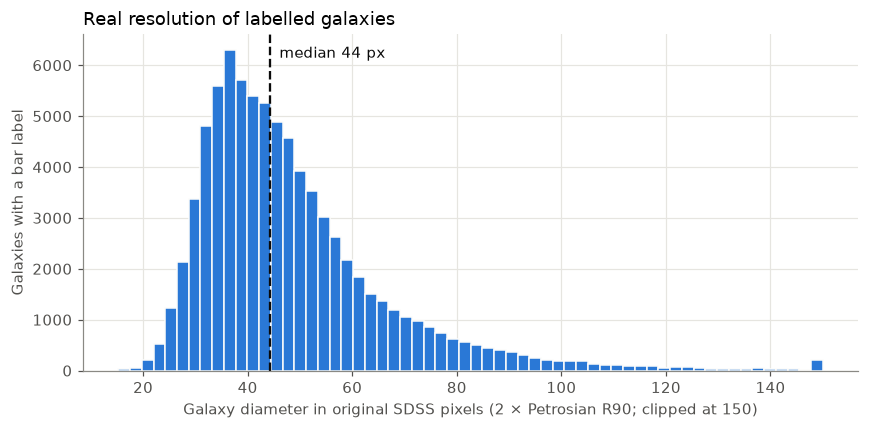

≤ 32 px     11.9%
≤ 64 px     84.7%
≤ 128 px    99.4%


In [10]:
labelled_px = df.loc[df["bar_usable"], "native_px"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(labelled_px.clip(upper=150), bins=60, color=BAR_COLOR, edgecolor=SURFACE, linewidth=1)
median_px = labelled_px.median()
ax.axvline(median_px, color=INK, linewidth=1.5, linestyle="--")
ax.annotate(f"median {median_px:.0f} px", xy=(median_px, ax.get_ylim()[1] * 0.93),
            xytext=(6, 0), textcoords="offset points", color=INK)
ax.set_xlabel("Galaxy diameter in original SDSS pixels (2 × Petrosian R90; clipped at 150)")
ax.set_ylabel("Galaxies with a bar label")
ax.set_title("Real resolution of labelled galaxies")
save(fig, "native_resolution")

print(pd.Series({f"≤ {k} px": (labelled_px <= k).mean() for k in (32, 64, 128)}).map("{:.1%}".format).to_string())

## Visual check: what the model will see

Each image below is centre-cropped to 212 px, as in the training pipeline. The rows are confident
examples of each label plus ambiguous bars. If the labels are trustworthy, the confident rows
should be easy to tell apart by eye. The Zenodo README recommends exactly this spot-check.

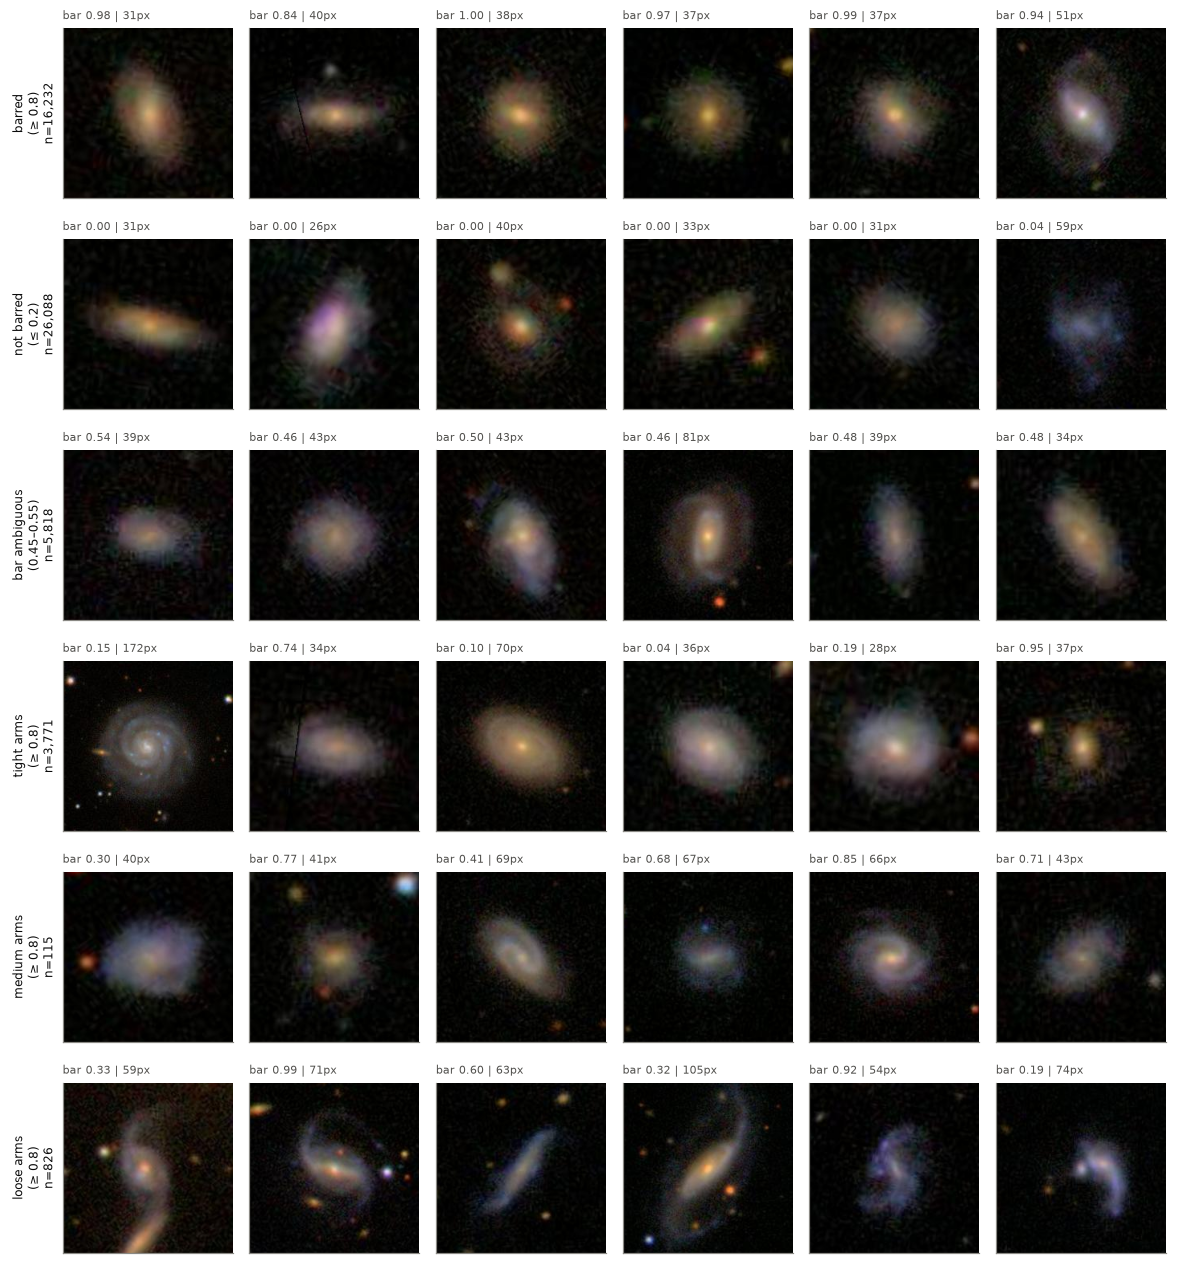

In [11]:
rng = np.random.default_rng(42)
n_cols = 6
groups = {
    f"barred\n(≥ {CONFIDENT})": df["bar_usable"] & (df["t03_bar"] >= CONFIDENT),
    f"not barred\n(≤ {1 - CONFIDENT:.1f})": df["bar_usable"] & (df["t03_bar"] <= 1 - CONFIDENT),
    "bar ambiguous\n(0.45–0.55)": df["bar_usable"] & df["t03_bar"].between(0.45, 0.55),
    **{
        f"{name} arms\n(≥ {CONFIDENT})": df["winding_usable"] & (df[col] >= CONFIDENT)
        for col, name in zip(WINDING_COLS, WINDING_NAMES)
    },
}


def centre_crop(path: str, fraction: float = 0.5) -> Image.Image:
    image = Image.open(path)
    w, h = image.size
    dw, dh = int(w * (1 - fraction) / 2), int(h * (1 - fraction) / 2)
    return image.crop((dw, dh, w - dw, h - dh))


fig, axes = plt.subplots(len(groups), n_cols, figsize=(n_cols * 1.8, len(groups) * 1.95))
for row, (label, mask) in zip(axes, groups.items()):
    pool = df[mask]
    picks = pool.iloc[rng.choice(len(pool), size=min(n_cols, len(pool)), replace=False)]
    for ax, (_, galaxy) in zip(row, picks.iterrows()):
        ax.imshow(centre_crop(galaxy["image_path"]))
        ax.set_title(f"bar {galaxy['t03_bar']:.2f} | {galaxy['native_px']:.0f}px", fontsize=7, color=INK_SECONDARY)
    for ax in row:
        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)
    row[0].set_ylabel(f"{label}\nn={len(pool):,}", fontsize=8, color=INK)
save(fig, "examples")

**Things to notice:**

- Confident winding labels are rare and lopsided: mostly *tight*, very few *medium*. A
  confident-only winding evaluation would mostly test "tight vs not", which is another reason to
  treat winding as regression on the vote fractions.
- Some confident "tight" galaxies show no visible arms at this resolution. Volunteers may have
  picked *tight* when the arms were barely resolved, so part of the winding label is really
  "can't see arms clearly". Check per-size-bin errors before concluding that one architecture
  reads arms better.